       mfcc_1      mfcc_2      mfcc_3     mfcc_4     mfcc_5     mfcc_6  \
0 -492.671949  147.068811  -76.404904 -54.999308  -0.226016 -37.168935   
1 -450.613730  180.368273  -85.665103 -77.750988  -7.483319 -37.498395   
2 -537.986710  204.549656 -105.325511 -59.490086   3.088097 -37.844152   
3 -607.907541  226.445508 -156.033689 -21.049384  11.528269 -48.752307   
4 -612.530724  137.294089  -41.315163 -45.914490  -1.927614 -22.939446   

      mfcc_7     mfcc_8     mfcc_9    mfcc_10    mfcc_11    mfcc_12  \
0 -41.597508  -9.428412  -8.221461 -18.054654 -15.622431 -14.517657   
1 -39.846435  -0.473004  -6.796316 -28.916318 -22.095230 -14.659583   
2 -25.471458  -6.562715 -22.174805 -29.473311 -25.111846 -15.276430   
3 -14.012730 -24.005423 -25.439083 -21.761577 -32.164367 -10.539685   
4 -36.647825 -16.339434  -8.087511 -14.809998 -17.444390 -16.041396   

     mfcc_13     centroid    bandwidth   contrast       zcr label  
0 -18.351768  1753.144207  1066.922546  22.436625  0.059387 

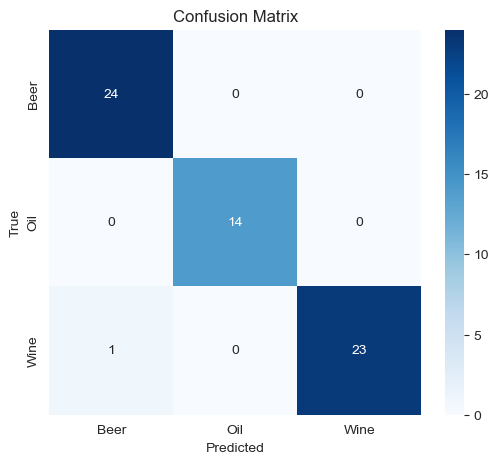

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# === 1. Load dataset ===
df = pd.read_csv("liquid_audio_features_filtered.csv")
print(df.head())

# === 2. Split features and labels ===
X = df.drop("label", axis=1).values
y = df["label"].values

# === 3. Encode labels ===
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# === 4. Train/Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# === 5. Optional - Scale features ===
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === 6. Train Classifier ===
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# === 7. Evaluate ===
y_pred = clf.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# === 8. Confusion Matrix ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()
